## 2 Global Navigation

### [2A] Module Overview

The global navigation module transforms the computer vision output into a collision-free reference trajectory. It was designed with modularity in mind, so that it is importable from anywhere. The module is spread accross multiple files for better organization and separation of concerns. The specific directory structure is shown below.

>```txt
>classes/gp/
>├── __init__.py     # init file
>├── graph.py        # VisibilityGraph class
>├── main.py         # standalone
>├── planner.py      # GlobalPlanner class
>├── plotter.py      # Plotter class
>└── utils.py        # utilities
>```

The main API used for the project are the `GlobalPlanner` and `Plotter` classes. The former houses the general planning functionality, while the latter provides useful plots: either of generated paths, or comparison plots. Import of the aforementioned classes is, as already mentioned, accessible from anywhere within the project using

In [ ]:
# Module import (API used for the project)
from classes.gp import GlobalPlanner, Plotter

which exposes all the necessary functionality of global planning (and related plotting). The major ones are the `.plan()` method, owned by `GlobalPlanner`, and the `.path()` method, owned by `Plotter`.

### [2B] Independent Showcase

To show the independent functionality of the module, we provide dummy computer vision data below. Generally, the computer vision output (and thereby global planning input) obeys the following structure:

>```python
>cv_data = [
>    [W, H],                                     # map size (width, height)
>    np.array([[obs0_v0], ..., [obs0_vn]]),      # vertices of obstacle 0
>    ...,                                        # vertices of other obs.
>    np.array([[obsM_v0], ..., [obsM_vk]]),      # vertices of obstacle M
>    np.array([s_x, s_y]),                       # start coordinates (x,y)
>    np.array([g_x, g_y])                        # goal coordinates (x,y)
>]
>```

which you are free to change to get different results, but be aware of edge cases where for some maps, no path can be found. All coordinates are in the computer vision frame. Using this information, the planner computes a reference path based on a visibility graph and an A* search (to be discussed shortly).

In [ ]:
import numpy as np

# Load "CV" data
data = [
        [260.0, 200.0],
        np.array([[60, 40], [90, 40], [90, 80], [60, 80]]),
        np.array([[130, 40], [200, 40], [200, 70], [130, 70]]),
        np.array([[120, 120], [160, 120], [160, 170], [120, 170]]),
        np.array([[40, 130], [70, 140], [65, 160], [35, 170], [25, 150]]),
        np.array([[200, 110], [230, 120], [220, 145]]),
        np.array([[180, 10], [230, 15], [225, 35], [175, 30]]),
        np.array([20, 20]),                                                 # change recommended
        np.array([240, 180]),                                               # change recommended
    ]

Finally, let us explore the aforementioned API. First, we need to initialize an instance of both classes. Besides the required `data` argument, the planner can also take additional arguments. Namely the Thymio's radius and the spacing of intermediate goals along the reference path. Below, you can change these values to see their effects.

In [ ]:
RADIUS = 5.0    # Thymio radius (circumscribed circle)
SPACING = 1.0   # Intermediate goals spacing

# Create GlobalPlanner instance
planner = GlobalPlanner(data, radius=RADIUS, spacing=SPACING)

# Create Plotter instance
plotter = Plotter(planner)

Notice that the instance creation of `Plotter` requires an instance of `Planner`. With both objects now initialized, a reference path can be planned and plotted using the methods mentioned above. In code:

In [ ]:
segments = planner.plan()   # Plan the reference path
# plotter.plain()           # Uncomment to see plain course
# plotter.visibility()      # Uncomment to see visibility graph
plotter.path()              # Show the reference path

In addition to `.path()`, the API exposes other methods of the `Plotter` class. These allow plotting of either the plain course, or the visibility graph. Furthermore, if one has a log of robot states throughout the run, specifically the coordinates it hit, the `Plotter` API provides a `.paths()` method to overlay the robot actual path on top.

Lastly, for the case of kidnapping, the `.plan()` method of the `GlobalPlanner` class has an optional argument (`start`), which is crucial for replanning from a new position once the robot has been placed back down on the map. Notice that for replanning, no other information is required as the map size, the obstacles, and the goal position all stay constant. The replanning using a new start is shown below.

In [ ]:
new_start = [150.0, 10.0]               # Choose a new start

segments2 = planner.plan(new_start)     # Replan with the new start
# plotter.plain()                       # Uncomment to see plain course
# plotter.visibility()                  # Uncomment to see visibility graph
plotter.path()                          # Update the reference path

This finalizes the independent showcase of the module. The `segments` returned by the `.plan()` method are passed on to the motion control module as goals to follow. For a deep-dive into global planning, see [2C].

### [2C] Deep-Dive & Explanation

In [ ]:
%run main.py

## [3] Extended Kalman Filter
### [3A] Module Overview
An Extended Kalman Filter was implemented for state estimation of the robot. This filter combines robot position (x, y, and angle) measurements from the computer vision with a basic two-wheel differential robot motion model for state estimation, using motor speeds produced from the PID controller (next section) as inputs.

The code for the EKF is located in `classes/ekf.py`. To use it, an instance of the `EKF` class must be initialized with the following parameters:
- Motion model error covarince matrix `Q`
- Measurement model error covariance matrix `R`
- Initial state
- Robot wheel-to-wheel width (used in the motion model) `T`
- Time step `dt`

After initialization, the next state can be calculated by calling the function `generate_next_state(inputs, measures)`, which takes as parameters the system inputs (motor velocities) and measurements (positions from CV) at the current time.

### [3B] Independent Showcase
The following code blocks provide a simple simulation demonstrating the functionality of the EKF. At each time step, the robot is provided with a random input. Its next state is moved according to the motion model and measurements are generated at each step, with noise added based on the measured variances (see next subsection).

We first import the required modules, select the starting pose of the robot, and initialize the EKF.

In [ ]:
from classes.ekf import EKF
import constants
import numpy as np
import matplotlib.pyplot as plt
import random

# Set start at the origin
# State takes the form [x, y, v, theta, w]
start_pose = [0., 0., 0., 0., 0.]
dt = constants.general['dt']

# Initialize EKF
ekf = EKF(
    np.diag(constants.ekf['move_vars']), # Q
    np.diag(constants.ekf['measure_vars']), # R
    start_pose,
    constants.robot['wheel_base'],
    dt
)

We can then run the entire loop, which takes the following steps:
- 

Sdfsf


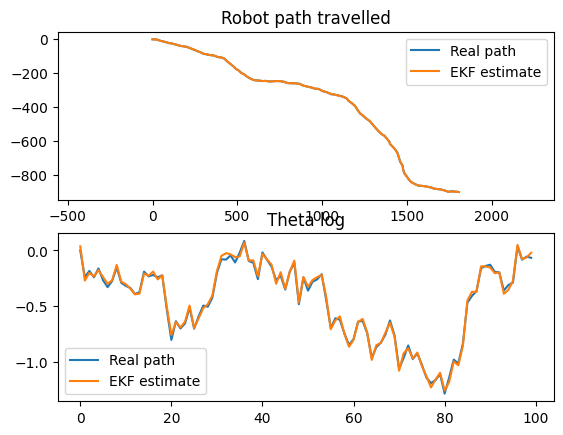

In [ ]:
# Logs for plotting later
real_pose_log = [start_pose]
ekf_pose_log = []

# Initial inputs are 0
left_mtr = 0
right_mtr = 0

iters = 100
for n in range(iters):
    prev_pose = real_pose_log[-1]

    # Get ideal measurements from current state (x, y, theta)
    measures_ideal = [prev_pose[0], prev_pose[1], prev_pose[3]]

    # Add noise based on measured variances (constants.ekf['measure_vars'])
    measures_noisy = measures_ideal
    for i in range(len(measures_noisy)):
        measures_noisy[i] += random.gauss(0, np.sqrt(constants.ekf['measure_vars'][i]))

    # Get state estimate from EKF
    est_pose = ekf.generate_next_state(
                inputs=[left_mtr, right_mtr],
                measures=measures_noisy
                )
    ekf_pose_log.append(est_pose)

    # Break if we're at the last step, we don't care about the last position
    if n == iters-1:
        print("Sdfsf")
        break

    # Pick new random inputs based on our normal driving velocity ranges
    left_mtr = random.randrange(50, 150)
    right_mtr = random.randrange(50, 150)

    # Calculate linear and angular velocity for simulation purposes
    v = (left_mtr + right_mtr)/2
    w = (right_mtr - left_mtr)/constants.robot['wheel_base']

    # Calculate theoretical next state
    prev_x, prev_y, prev_v, prev_theta, prev_w = real_pose_log[-1]

    next_x = prev_x + v*np.cos(prev_theta)*dt
    next_y = prev_y + v*np.sin(prev_theta)*dt
    next_theta = prev_theta + w*dt

    real_pose_nonoise = [next_x, next_y, v, next_theta, w]

    # Add noise
    real_pose = real_pose_nonoise
    for i in range(len(real_pose)):
        real_pose[i] += random.gauss(0, np.sqrt(constants.ekf['move_vars'][i]))

    real_pose_log.append(real_pose)

# Plot path
x_log_real = [state[0] for state in real_pose_log] 
y_log_real = [state[1] for state in real_pose_log]
theta_log_real = [state[3] for state in real_pose_log]

x_log_ekf = [state[0] for state in ekf_pose_log] 
y_log_ekf = [state[1] for state in ekf_pose_log]
theta_log_ekf = [state[3] for state in ekf_pose_log]

plt.subplot(2, 1, 1)
plt.plot(x_log_real, y_log_real)
plt.plot(x_log_ekf, y_log_ekf)
plt.title("Robot path travelled")
plt.legend(["Real path", "EKF estimate"])
plt.axis('equal')

plt.subplot(2, 1, 2)
plt.plot(theta_log_real)
plt.plot(theta_log_ekf)
plt.legend(["Real path", "EKF estimate"])
plt.title("Theta log")
plt.show()


## [4] Motion Control
### [4A] Module Overview
To allow the robot to smoothly and accurately follow the desired path, a PID controller was implemented. This controller is located in the `PID` class in `classes/motion_control.py`.

To use the PID controller, an instance of the `PID` class must first be created. Then, the `get_motor_vels(start, goal)` function can be called every time robot's motion requires an update, where `start` and `goal` take the form of a pose in the form `[x, y, theta]`. The class stores previous error values in order to determine the error integrals and derivatives, and provides plotting capability. The PID constants used are stored in the dictionary `pid` in `constants.py`. 

### [4B] Independent showcase
The following code provides a simple simulation demonstrating the PID controller at work. The robot starts facing vertically, and must make a 90 degree turn to end up at a point to the right of where it began, facing horizontally.

We first import the required modules and initialize the PID class, passing it the desired PID constants.

In [ ]:
import constants
from classes.motion_control import PID
import matplotlib.pyplot as plt
import numpy as np

# Select PID constants
pid_consts = {
    'theta': {  
        'kp': 10,
        'ki': 0,
        'kd': 0, 
    },
    'beta': {
        'kp': 80,
        'ki': 10,
        'kd': 0,
    }
}

# Initialize PID class
pid = PID(pid_consts)

Then, we can set sample data. The starting point is set to the origin, with the robot at an angle of 90 degrees (facing upwards). The end goal is set to a point to the right of this, with an angle of 0. The robot will have to make a sharp turn to and then proceed towards the end goal.

In [ ]:
# Sample data
start = [0, 0, 0, np.pi/2, 0] # State stores [x, y, v, theta, w]
end = [500, 0, 0]
current_pose = start
dt = 0.2

Next, we define a helper function to determine whether or not we have reached our end goal, within a specified tolerance. Note that angle is ignored here - we only care whether we have reached the correct (x, y) position.

In [ ]:
# Use this function to determine whether we've reached our goal,
# wtihin the allowed buffer distance. Note that we ignore angle
# for this comparison.
def reached_goal(current, goal):
    px, py = current[0], current[1]
    gx, gy = goal[0], goal[1]

    # Check that both distances are less than the buffer
    return (abs(px - gx) < constants.general['goal_buffer'] and
        abs(py - gy) < constants.general['goal_buffer'])

We can then run the main simulation loop, using the PID class to get updated motor velocities at each time step.

In [ ]:
# Log the robot's state at each timestep
state_log = [start]

max_iters = 1000
i = 0
# Run main loop
while not reached_goal(current_pose, end):
    if i > max_iters:
        print("Could not reach goal")
        break
    # Get motor velocities from PID. This would be input to the robot.
    mtr_left, mtr_right = pid.get_mtr_vels(current_pose, end)

    # Calculate linear and angular velocity for simulation purposes
    v = (mtr_left + mtr_right)/2
    w = (mtr_right - mtr_left)/constants.robot['wheel_base']

    # Update state for simulation purposes
    prev_x, prev_y, prev_v, prev_theta, prev_w = state_log[-1]

    next_x = prev_x + v*np.cos(prev_theta)*dt
    next_y = prev_y + v*np.sin(prev_theta)*dt
    next_theta = prev_theta + w*dt

    current_pose = [next_x, next_y, v, next_theta, w]
    state_log.append(current_pose)
    i += 1

Finally, we generate plots of the robot's path travelled, and informative PID logs.

In [ ]:
# Plot path
x_log = [state[0] for state in state_log] 
y_log = [state[1] for state in state_log]
theta_log = [state[3] for state in state_log]

plt.subplot(2, 1, 1)
plt.plot([start[0], end[0]], [start[1], end[1]])
plt.plot(x_log, y_log)
plt.title("Robot path travelled")
plt.legend(["Desired path", "Actual path"])
plt.axis('equal')

plt.subplot(2, 1, 2)
plt.plot(theta_log)
plt.title("Theta log")
plt.show()

# Plot PID error logs
pid.plot()

### [4C] Deep Dive and Explanation

MEDINA NOTES - THINGS TO MENTION
- set_motors function takes real velocities
- that whole real to robot conversion
- add PID theta error logs
- Q and R are assumed diagonal

OTHER
- should we submit with PID constants that work in sim or in real life?